# 10 - A1: LFCC + GMM (official ASVspoof 2019 B02 baseline)

**Question this notebook answers:** does the official B02 recipe -- 60-dimensional linear-frequency cepstral coefficients (LFCC; 20 static + delta + delta-delta), two 512-component diagonal Gaussian mixture models (GMMs), mean-per-frame log-likelihood-ratio scoring -- separate bona fide from spoof speech on the ASVspoof 2019 logical access (LA) corpus, and how does our reproduction sit next to (never directly compared with, only shown beside a `literature`-tagged reference) the published B02 eval numbers (minimum tandem detection cost function (min t-DCF) 0.2116, equal error rate (EER) 8.09%, arXiv:1904.05441 Table 1)?

**Every B02 choice this notebook relies on** is documented and sourced in `Miscellaneous/research/knowledge/methods/b02-lfcc-gmm.md` (read directly from the official baseline code) and `src/audio_df/features/lfcc_b02.py`'s module docstring:

- 20 ms Hamming window, 10 ms hop (50% overlap), 512-point fast Fourier transform (FFT).
- 20 linear triangular filters spanning **0-8000 Hz** (not 30 Hz-8 kHz; the 0 Hz lower edge is what the official code uses).
- Pre-emphasis 0.97, `log10` (not natural log), orthonormal type-II discrete cosine transform (DCT-II), no cepstral mean and variance normalisation (CMVN).
- 20 static (19 + 0th cepstral coefficient) + 20 delta + 20 delta-delta = 60 dims. Delta/delta-delta use the official `deltas.m`'s exact finite impulse response (FIR) filter (`official_deltas`, transcribed from `filter([hlen:-1:-hlen], 1, xx)` with edge-replicated padding) -- for w=3 this is `x[t+1]-x[t-1]` with **no division by 2**, unlike `features.add_deltas`'s normalised `np.gradient`.
- Two independent 512-component diagonal-covariance GMMs (bona fide, spoof), trained on the TRAIN partition only, random-init expectation-maximisation (EM), 10 iterations.
- Score = mean per-frame log-likelihood-ratio (bona fide GMM minus spoof GMM) over the **whole utterance** -- A1 does not use this project's usual 4 s crop.

**Notebook rule (tasks/CONVENTIONS.md):** this notebook holds questions, plots and interpretation only; every computation calls into `src/audio_df`.

**Do not run the actual train/score commands from inside this notebook.** Cell 4 prints the exact terminal commands; run them in a terminal (ideally under `caffeinate -i`) so a long job survives the notebook's kernel restarting or the laptop trying to sleep.

## Cell 1 - config, resource limits, current memory status

Loads `configs/a1_lfcc_gmm.yaml` and `configs/resources.yaml`, and shows this machine's *current* memory status (`audio_df.runtime.resources.memory_status`) -- the same check `experiment_run` uses to refuse starting a heavy job under pressure.

In [1]:
# Work from the repo root, so config and manifest paths (all relative to it) resolve
# wherever the notebook is opened from (VS Code starts kernels in notebooks/).
import os
from pathlib import Path

REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(REPO_ROOT)
print("working directory:", REPO_ROOT)

working directory: /Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2


In [2]:
from pathlib import Path

import yaml

from audio_df.pipelines.run_a1 import load_config
from audio_df.runtime.resources import load_resources, memory_status

cfg = load_config("configs/a1_lfcc_gmm.yaml")
resources_cfg = load_resources("configs/resources.yaml")

print("A1 config summary:")
print(yaml.safe_dump({"features": cfg["features"], "gmm": cfg["gmm"]}, sort_keys=False))

print("Resource limits (configs/resources.yaml):")
print(yaml.safe_dump(resources_cfg["resources"], sort_keys=False))

print("Current memory status:")
print(memory_status())

/Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


A1 config summary:
features:
  name: lfcc_b02
  window_ms: 20
  hop_ms: 10
  n_fft: 512
  n_filters: 20
  fmin: 0.0
  fmax: null
  preemph: 0.97
  delta_window: 3
  total_dims: 60
gmm:
  n_components: 512
  covariance: diag
  em_iters: 10
  init: random_frames
  chunk_frames: 50000
  variance_floor: 0.001
  init_sample_size: 200000

Resource limits (configs/resources.yaml):
mps_high_watermark_ratio: 0.3
cpu_threads: 4
max_loader_workers: 2
max_loader_workers_ssl: 1
ssl_extract_batch_size: 4
max_ffmpeg_workers: 2
min_free_disk_gb: 30
timing_run_clips: 200
chunk_size: 512
memory_guard:
  poll: between_chunks
  swap_growth_limit_gb: 1.0
  pause_on: warn
  exit_on: critical
close_before_heavy_jobs:
- Arc
- Outlook
- Word
- mysqld

Current memory status:
{'pressure_level': 2, 'pressure_name': 'warn', 'swap_used_gb': 2.34619140625, 'swap_total_gb': 3.0, 'rss_mb': 402.9375}


## Cell 2 - the LFCC pipeline on two real clips (one bona fide, one spoof)

Cheap: one utterance per class. Gated on the dataset being present at `configs/data.yaml: dataset.root`: if the prepared manifests are missing, the cell prints a clear message and skips instead of raising. Training and scoring on the full corpus are never started from the notebook; they run from a terminal (Cell 4).

**What the stored run shows:** the first train bona fide clip (`LA_T_1138215`, 345 frames) and the first train spoof clip (`LA_T_1004644`, 192 frames). The bona fide waveform has a long quiet stretch before the speech starts; the spoof waveform starts speaking almost at once. In the LFCC images, row 0 (c0, overall level) is the darkest band, and rows 20 and 40 (the delta and delta-delta of c0) carry the sharpest frame-to-frame changes, at speech onsets and offsets.

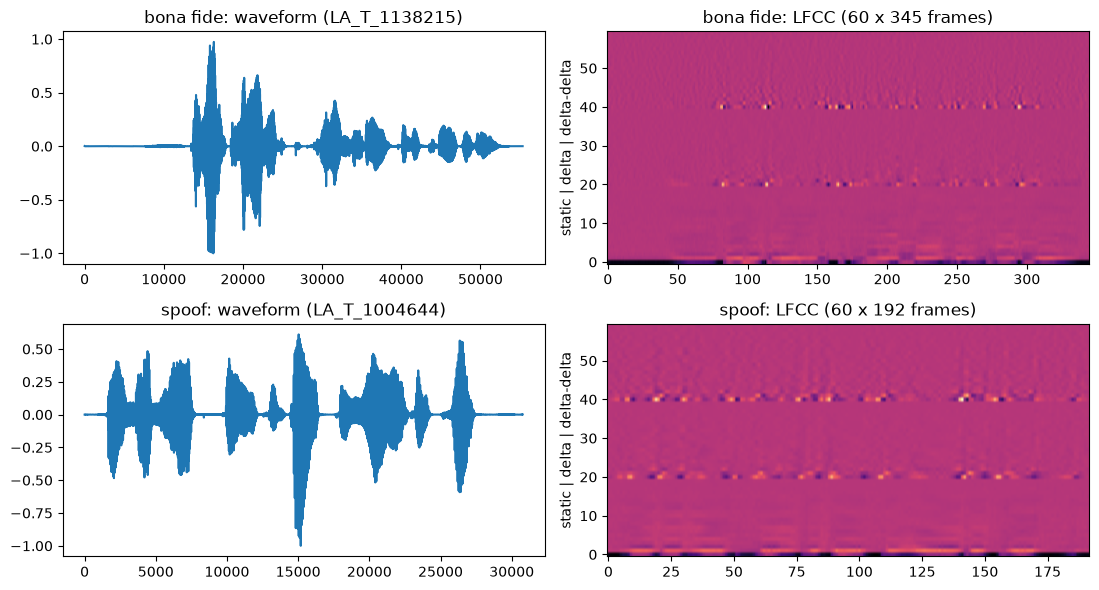

In [3]:
import matplotlib.pyplot as plt
import pandas as pd

from audio_df.features.audio import load_audio, preprocess
from audio_df.features.lfcc_b02 import extract_lfcc_b02

train_manifest_path = Path(cfg["data"]["train"])
if not train_manifest_path.exists():
    print(f"{train_manifest_path} not found -- run scripts/prepare_data.py first. Skipping cell 2.")
else:
    train_df = pd.read_csv(train_manifest_path)
    bona_row = train_df[train_df["label"] == "bonafide"].iloc[0]
    spoof_row = train_df[train_df["label"] == "spoof"].iloc[0]

    fig, axes = plt.subplots(2, 2, figsize=(11, 6))
    for ax_row, row, title in ((axes[0], bona_row, "bona fide"), (axes[1], spoof_row, "spoof")):
        x, sr = load_audio(row["path"], target_sr=cfg["preprocessing"]["sample_rate"])
        x = preprocess(x, sr, silence_mode=cfg["preprocessing"]["silence_mode"], crop_seconds=None)
        feats = extract_lfcc_b02(x, sr=sr, cfg=cfg["features"])

        ax_row[0].plot(x)
        ax_row[0].set_title(f"{title}: waveform ({row['utt_id']})")
        im = ax_row[1].imshow(feats.T, aspect="auto", origin="lower", cmap="magma")
        ax_row[1].set_title(f"{title}: LFCC (60 x {feats.shape[0]} frames)")
        ax_row[1].set_ylabel("static | delta | delta-delta")
    fig.tight_layout()
    plt.show()

## Cell 3 - the 200-clip timing run

Calls exactly the function `run_a1.py timing` uses (`timing_run` over `extract_frames_for_row`), so the notebook and the command-line interface (CLI) never drift apart. The timed function covers loading, preprocessing and LFCC extraction only, not GMM training. Read the printed extrapolation as a **lower bound**: this is a fanless machine that throttles under sustained load.

**What the stored run shows:** a median of 1.88 ms per clip (519.57 clips per second, peak resident memory 473.0 MB), extrapolated to 0.01 h for all 25,380 train clips. The registered full A1 training run took 20.6 min end to end (`runs/REGISTRY.md`, `E-20261001-e1-a1-raw`), so feature extraction is a small part of the cost and the 512-component EM dominates.

In [4]:
from audio_df.pipelines.run_a1 import extract_frames_for_row
from audio_df.runtime.resources import format_timing, timing_run

if not train_manifest_path.exists():
    print("Dataset not present -- skipping the timing run.")
else:
    n = min(200, len(train_df))
    sample_rows = list(train_df.head(n).itertuples(index=False))
    result = timing_run(
        lambda row: extract_frames_for_row(row, cfg),
        sample_rows,
        n=len(sample_rows),
        total_items=len(train_df),
        cfg=resources_cfg,
    )
    print(format_timing(result))

timed 200 items
  median 1.88 ms/item, mean 1.92 ms/item, p90 2.33 ms/item
  519.57 items/sec, peak RSS 473.0 MB
  peak MPS allocation 0.5 MB
  swap 2.34619140625 GB -> 2.34619140625 GB, pressure 2 -> 2
  EXTRAPOLATED (not measured) for 25380 items: 0.01 h — a fanless machine throttles under sustained load, so a real full run will likely take longer than this.


## Cell 4 - the full run: exact terminal commands

Run these in a terminal, not in this notebook: the registered A1 training runs took between 20.6 min and 1.1 h on this machine (`runs/REGISTRY.md`), and a notebook kernel is not the place for that. `caffeinate -i` stops the laptop from sleeping mid-run; it does not prevent thermal throttling.

In [5]:
print("# 1) train both GMMs on raw TRAIN, then score raw dev+eval:")
print("caffeinate -i uv run python -m audio_df.pipelines.run_a1 train --exp e1")
print()
print("# 2) if interrupted (Ctrl-C, memory pressure, crash), resume the same run:")
print("caffeinate -i uv run python -m audio_df.pipelines.run_a1 train --exp e1 --resume")
print()
print("# 3) trimmed diagnostic: score the RAW-trained GMMs against trimmed eval + In-the-Wild")
print("#    (there is no trimmed *training* for A1 -- see run_a1.py's module docstring):")
print(
    "uv run python -m audio_df.pipelines.run_a1 score "
    "--model-from runs/E-<date>-e1-a1-raw --exp e1 "
    "--silence-mode trimmed --testsets eval,itw"
)
print()
print("# 4) turn score files into metrics.json (never inside run_a1.py itself):")
print("uv run python scripts/score_experiment.py runs/E-<date>-e1-a1-raw")
print(
    "uv run python scripts/score_experiment.py runs/E-<date>-e1-a1-trimmed "
    "--threshold-from runs/E-<date>-e1-a1-raw"
)
print()
print("# 5) regenerate the E1...E6 summary tables:")
print("uv run python scripts/make_tables.py")

# 1) train both GMMs on raw TRAIN, then score raw dev+eval:
caffeinate -i uv run python -m audio_df.pipelines.run_a1 train --exp e1

# 2) if interrupted (Ctrl-C, memory pressure, crash), resume the same run:
caffeinate -i uv run python -m audio_df.pipelines.run_a1 train --exp e1 --resume

# 3) trimmed diagnostic: score the RAW-trained GMMs against trimmed eval + In-the-Wild
#    (there is no trimmed *training* for A1 -- see run_a1.py's module docstring):
uv run python -m audio_df.pipelines.run_a1 score --model-from runs/E-<date>-e1-a1-raw --exp e1 --silence-mode trimmed --testsets eval,itw

# 4) turn score files into metrics.json (never inside run_a1.py itself):
uv run python scripts/score_experiment.py runs/E-<date>-e1-a1-raw
uv run python scripts/score_experiment.py runs/E-<date>-e1-a1-trimmed --threshold-from runs/E-<date>-e1-a1-raw

# 5) regenerate the E1...E6 summary tables:
uv run python scripts/make_tables.py


## Cell 5 - after the run: scores, histograms, metrics, the literature reference

Gated on `experiments/` containing a finished A1 run: set `exp_id` below to the directory the terminal run produced. In the stored output `exp_id` is unset, so no histogram or metrics are drawn here.

**Registered results** (`runs/REGISTRY.md`): the A1 run `E-20261001-e1-a1-raw` measured **2.62 % EER on dev** (known attacks A01-A06) and **9.56 % on eval** (unseen attacks A07-A19). Scoring the same raw-trained GMMs on silence-trimmed eval audio (`E-20261001-e1-a1-trimmed`) measured 19.84 %, and on In-the-Wild audio 58.04 % raw and 61.36 % trimmed (`E-20261001-e3-a1-raw`, `E-20261001-e3-a1-trimmed`). The published B02 figure of 8.09 % eval EER is a `literature` reference shown beside these, not a like-for-like comparison.

In [6]:
exp_id = None  # e.g. "E-20261001-e1-a1-raw" once you have run the terminal commands above

if exp_id is None:
    print("Set exp_id above to an runs/<exp_id> directory produced by the terminal run.")
else:
    exp_dir = Path("experiments") / exp_id
    eval_scores = pd.read_csv(exp_dir / "scores" / "eval.csv")

    fig, ax = plt.subplots(figsize=(7, 4))
    for label, color in (("bonafide", "tab:blue"), ("spoof", "tab:red")):
        subset = eval_scores.loc[eval_scores["label"] == label, "score"]
        ax.hist(subset, bins=40, alpha=0.6, label=label, color=color)
    ax.set_xlabel("score (higher = more bona fide)")
    ax.legend()
    ax.set_title(f"{exp_id}: eval score histogram by class")
    plt.show()

    if "attack_id" in eval_scores.columns:
        fig, ax = plt.subplots(figsize=(9, 4))
        spoof_only = eval_scores[eval_scores["label"] == "spoof"]
        spoof_only.boxplot(column="score", by="attack_id", ax=ax)
        ax.set_title(f"{exp_id}: eval spoof score by attack (A07-A19)")
        plt.suptitle("")
        plt.show()

    metrics_path = exp_dir / "metrics.json"
    if metrics_path.exists():
        import json

        metrics = json.loads(metrics_path.read_text())
        print("eval metrics (this run):", metrics["testsets"].get("eval"))
    else:
        print(f"{metrics_path} not found -- run scripts/score_experiment.py first.")

    ref = cfg["literature_reference"]
    print(
        f"\nLITERATURE reference (never compared directly with the run above): "
        f"{ref['source']}, {ref['scenario']} {ref['split']}: "
        f"EER={ref['eer_percent']}%, min t-DCF={ref['min_tdcf']} (tag: {ref['tag']})"
    )

Set exp_id above to an runs/<exp_id> directory produced by the terminal run.
